# ReviewPulse — 15% Portfolio Project

**Task:** Indonesian product-review analysis for seller/UMKM operations.

**MVP goals**
1. Sentiment classification from review text.
2. Emotion classification from review text.
3. Keyword / issue summary for uploaded or held-out reviews.
4. Export reproducible reports, plots, models, and a small inference sample.

> This notebook starts with a dataset audit before deciding whether TF-IDF or transformer modeling is appropriate.

In [1]:
import os, sys, time
print("=== REVIEWPULSE 15% — FULL PIPELINE BOOT ===", flush=True)
print("[BOOT] Python:", sys.version, flush=True)
print("[BOOT] cwd:", os.getcwd(), flush=True)
print("[BOOT] heartbeat 1", flush=True)
time.sleep(1)
print("[BOOT] heartbeat 2", flush=True)
with open("/kaggle/working/REVIEWPULSE_15PCT_STARTED.txt", "w", encoding="utf-8") as f:
    f.write("started\n")
print("=== HEARTBEAT OK ===", flush=True)

=== REVIEWPULSE 15% — FULL PIPELINE BOOT ===
[BOOT] Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
[BOOT] cwd: /kaggle/working
[BOOT] heartbeat 1
[BOOT] heartbeat 2
=== HEARTBEAT OK ===


## 1. Environment and dependencies

In [2]:
import importlib.util, subprocess, sys

required = {
    "sklearn": "scikit-learn",
    "joblib": "joblib",
}
need = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]

if need:
    print("[SETUP] Installing:", need, flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need])

print("[SETUP] dependencies OK", flush=True)

[SETUP] dependencies OK


In [3]:
from pathlib import Path
import json, random, re, shutil, warnings, unicodedata
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

WORK = Path("/kaggle/working/reviewpulse_15pct")
REPORTS = WORK / "reports"
MODELS = WORK / "models"
ASSET_DATA = WORK / "assets" / "dataset"
ASSET_TRAIN = WORK / "assets" / "training"
ASSET_EVAL = WORK / "assets" / "evaluation"
ASSET_PRED = WORK / "assets" / "predictions"

for p in [WORK, REPORTS, MODELS, ASSET_DATA, ASSET_TRAIN, ASSET_EVAL, ASSET_PRED]:
    p.mkdir(parents=True, exist_ok=True)

print("[PATH] work:", WORK)

[PATH] work: /kaggle/working/reviewpulse_15pct


## 2. Locate the mounted dataset

In [4]:
CANONICAL_ROOT = Path(
    "/kaggle/input/datasets/loliwibu/product-reviews-dataset/"
    "Product Reviews Dataset for Emotions Classification Tasks - Indonesian (PRDECT-ID) Dataset"
)

candidates = [
    CANONICAL_ROOT / "PRDECT-ID Dataset.csv",
    CANONICAL_ROOT / "Product Reviews Dataset for Emotions Classification Tasks - Indonesian (PRDECT-ID) Dataset" / "PRDECT-ID Dataset.csv",
]

CSV_PATH = next((p for p in candidates if p.exists()), None)

if CSV_PATH is None:
    found = list(Path("/kaggle/input").rglob("PRDECT-ID Dataset.csv"))
    if not found:
        raise FileNotFoundError("PRDECT-ID Dataset.csv not found under /kaggle/input")
    CSV_PATH = found[0]

print("[DATA] CSV:", CSV_PATH)
assert CSV_PATH.exists()

[DATA] CSV: /kaggle/input/datasets/loliwibu/product-reviews-dataset/Product Reviews Dataset for Emotions Classification Tasks - Indonesian (PRDECT-ID) Dataset/PRDECT-ID Dataset.csv


## 3. Load and inspect source data

In [5]:
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(df.dtypes.to_frame("dtype"))

Shape: (5400, 11)
Columns: ['Category', 'Product Name', 'Location', 'Price', 'Overall Rating', 'Number Sold', 'Total Review', 'Customer Rating', 'Customer Review', 'Sentiment', 'Emotion']


,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion
0,Computers and Laptops,Wireless Keyboard i8 Mini TouchPad Mouse 2.4G ...,Jakarta Utara,53500,4.9,5449,2369,5,Alhamdulillah berfungsi dengan baik. Packaging...,Positive,Happy
1,Computers and Laptops,PAKET LISENSI WINDOWS 10 PRO DAN OFFICE 2019 O...,Kota Tangerang Selatan,72000,4.9,2359,1044,5,"barang bagus dan respon cepat, harga bersaing ...",Positive,Happy
2,Computers and Laptops,SSD Midasforce 128 Gb - Tanpa Caddy,Jakarta Barat,213000,5.0,12300,3573,5,"barang bagus, berfungsi dengan baik, seler ram...",Positive,Happy
3,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,bagus sesuai harapan penjual nya juga ramah. t...,Positive,Happy
4,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",Positive,Happy


,dtype
Category,object
Product Name,object
Location,object
Price,int64
Overall Rating,float64
Number Sold,int64
Total Review,int64
Customer Rating,int64
Customer Review,object
Sentiment,object


## 4. Source audit

The local copy provided for this project contains **5,400 rows × 11 columns**.  
This notebook does not assume label balance, duplicate safety, or language quality before auditing them.

In [6]:
EXPECTED = {
    "Category", "Product Name", "Location", "Price", "Overall Rating",
    "Number Sold", "Total Review", "Customer Rating", "Customer Review",
    "Sentiment", "Emotion"
}
assert EXPECTED.issubset(df.columns), EXPECTED - set(df.columns)

audit = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "missing_cells": int(df.isna().sum().sum()),
    "full_row_duplicates": int(df.duplicated().sum()),
    "duplicate_review_text_rows": int(df["Customer Review"].duplicated().sum()),
    "unique_review_texts": int(df["Customer Review"].nunique()),
    "sentiment_counts": df["Sentiment"].value_counts(dropna=False).to_dict(),
    "emotion_counts": df["Emotion"].value_counts(dropna=False).to_dict(),
    "category_counts": df["Category"].value_counts(dropna=False).to_dict(),
}

print(json.dumps(audit, indent=2, ensure_ascii=False))
(REPORTS / "source_audit.json").write_text(
    json.dumps(audit, indent=2, ensure_ascii=False), encoding="utf-8"
)

{
  "rows": 5400,
  "columns": 11,
  "missing_cells": 0,
  "full_row_duplicates": 7,
  "duplicate_review_text_rows": 95,
  "unique_review_texts": 5305,
  "sentiment_counts": {
    "Negative": 2821,
    "Positive": 2579
  },
  "emotion_counts": {
    "Happy": 1770,
    "Sadness": 1202,
    "Fear": 920,
    "Love": 809,
    "Anger": 699
  },
  "category_counts": {
    "Computers and Laptops": 200,
    "Toys and Hobbies": 200,
    "Food and Drink": 200,
    "Office & Stationery": 200,
    "Automotive": 200,
    "Animal Care": 200,
    "Body Care": 200,
    "Party Supplies and Craft": 200,
    "Carpentry": 200,
    "Other Products": 200,
    "Sport": 200,
    "Kitchen": 200,
    "Books": 200,
    "Camera": 200,
    "Gaming": 200,
    "Electronics": 200,
    "Kids and Baby Fashion": 200,
    "Men's Fashion": 200,
    "Muslim Fashion": 200,
    "Women's Fashion": 200,
    "Movies and Music": 200,
    "Health": 200,
    "Beauty": 200,
    "Phones and Tablets": 200,
    "Mother and Baby": 200,

1100

In [7]:
missing = (
    df.isna().sum()
      .sort_values(ascending=False)
      .rename("missing")
      .to_frame()
)
missing["missing_rate"] = missing["missing"] / len(df)
display(missing)
missing.to_csv(REPORTS / "missingness_report.csv")

,missing,missing_rate
Category,0,0.0
Product Name,0,0.0
Location,0,0.0
Price,0,0.0
Overall Rating,0,0.0
Number Sold,0,0.0
Total Review,0,0.0
Customer Rating,0,0.0
Customer Review,0,0.0
Sentiment,0,0.0


In [8]:
sentiment_counts = df["Sentiment"].value_counts()
emotion_counts = df["Emotion"].value_counts()
category_counts = df["Category"].value_counts()

print("Sentiment:")
display(sentiment_counts.to_frame("count"))
print("Emotion:")
display(emotion_counts.to_frame("count"))
print("Category:")
display(category_counts.to_frame("count"))

sentiment_counts.rename("count").to_csv(REPORTS / "sentiment_distribution.csv")
emotion_counts.rename("count").to_csv(REPORTS / "emotion_distribution.csv")
category_counts.rename("count").to_csv(REPORTS / "category_distribution.csv")

Sentiment:


,count
Sentiment,
Negative,2821
Positive,2579


Emotion:


,count
Emotion,
Happy,1770
Sadness,1202
Fear,920
Love,809
Anger,699


Category:


,count
Category,
Computers and Laptops,200
Toys and Hobbies,200
Food and Drink,200
Office & Stationery,200
Automotive,200
Animal Care,200
Body Care,200
Party Supplies and Craft,200
Carpentry,200


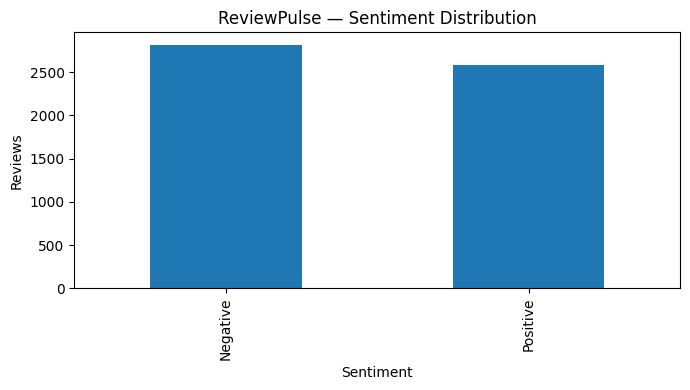

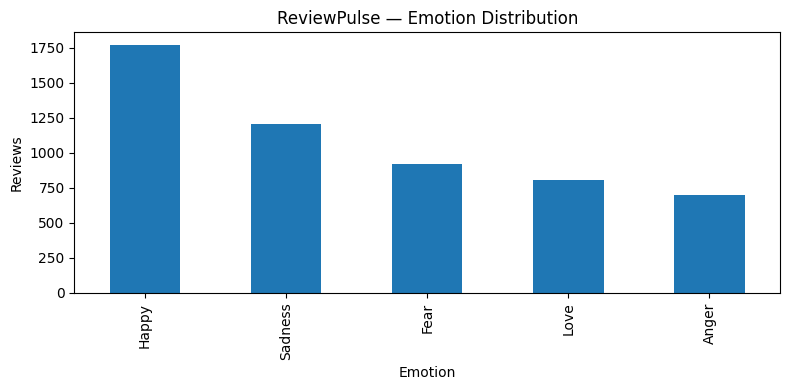

In [9]:
plt.figure(figsize=(7,4))
sentiment_counts.plot(kind="bar")
plt.title("ReviewPulse — Sentiment Distribution")
plt.ylabel("Reviews")
plt.xlabel("Sentiment")
plt.tight_layout()
plt.savefig(ASSET_DATA / "sentiment_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8,4))
emotion_counts.plot(kind="bar")
plt.title("ReviewPulse — Emotion Distribution")
plt.ylabel("Reviews")
plt.xlabel("Emotion")
plt.tight_layout()
plt.savefig(ASSET_DATA / "emotion_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Duplicate and label-conflict audit

In [10]:
review_label_audit = (
    df.groupby("Customer Review")
      .agg(
          rows=("Customer Review", "size"),
          sentiment_labels=("Sentiment", "nunique"),
          emotion_labels=("Emotion", "nunique"),
      )
      .reset_index()
)

sentiment_conflicts = review_label_audit[review_label_audit["sentiment_labels"] > 1].copy()
emotion_conflicts = review_label_audit[review_label_audit["emotion_labels"] > 1].copy()

print("Repeated review-text groups:", int((review_label_audit["rows"] > 1).sum()))
print("Sentiment-conflict texts:", len(sentiment_conflicts))
print("Emotion-conflict texts:", len(emotion_conflicts))

review_label_audit.to_csv(REPORTS / "review_duplicate_audit.csv", index=False)
sentiment_conflicts.to_csv(REPORTS / "sentiment_label_conflicts.csv", index=False)
emotion_conflicts.to_csv(REPORTS / "emotion_label_conflicts.csv", index=False)

Repeated review-text groups: 83
Sentiment-conflict texts: 0
Emotion-conflict texts: 25


### Duplicate policy

Repeated review text can leak across train/validation/test if rows are split independently.  
This notebook therefore assigns a normalized review-text **group ID** and splits by group.

- Exact/repeated text may remain in the dataset.
- The same normalized review text is not allowed to cross splits.
- Sentiment conflicts are reported separately.
- Emotion conflicts are reported separately and remain a dataset-quality limitation.

## 6. Text normalization for grouping only

In [11]:
def normalize_for_grouping(text: str) -> str:
    text = str(text)
    text = unicodedata.normalize("NFKC", text)
    text = text.lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

work = df.copy()
work["review_text"] = work["Customer Review"].astype(str).str.strip()
work["review_group"] = work["review_text"].map(normalize_for_grouping)

assert work["review_group"].notna().all()
print("Unique normalized review groups:", work["review_group"].nunique())

Unique normalized review groups: 5288


## 7. Group-aware train / validation / test split

In [12]:
# 70 / 15 / 15 approximately, grouped by normalized review text.
groups = work["review_group"]

gss1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
train_idx, temp_idx = next(gss1.split(work, groups=groups))

train = work.iloc[train_idx].copy()
temp = work.iloc[temp_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=SEED)
val_rel_idx, test_rel_idx = next(gss2.split(temp, groups=temp["review_group"]))

val = temp.iloc[val_rel_idx].copy()
test = temp.iloc[test_rel_idx].copy()

assert set(train["review_group"]).isdisjoint(set(val["review_group"]))
assert set(train["review_group"]).isdisjoint(set(test["review_group"]))
assert set(val["review_group"]).isdisjoint(set(test["review_group"]))

split_summary = pd.DataFrame([
    {
        "split": "train",
        "rows": len(train),
        "unique_review_groups": train["review_group"].nunique(),
        "sentiment_positive_rate": (train["Sentiment"] == "Positive").mean(),
    },
    {
        "split": "validation",
        "rows": len(val),
        "unique_review_groups": val["review_group"].nunique(),
        "sentiment_positive_rate": (val["Sentiment"] == "Positive").mean(),
    },
    {
        "split": "test",
        "rows": len(test),
        "unique_review_groups": test["review_group"].nunique(),
        "sentiment_positive_rate": (test["Sentiment"] == "Positive").mean(),
    },
])

display(split_summary)
split_summary.to_csv(REPORTS / "split_summary.csv", index=False)

,split,rows,unique_review_groups,sentiment_positive_rate
0,train,3782,3701,0.474881
1,validation,807,793,0.472119
2,test,811,794,0.495684


## 8. Metrics

Because sentiment is binary while emotion is 5-class, the main model-selection metric is:

- **Macro-F1** — treats each class equally.

Secondary metrics:

- Accuracy
- Balanced Accuracy
- Weighted F1
- Per-class precision / recall / F1

In [13]:
def classification_metrics(y_true, y_pred):
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    weighted_f1 = f1_score(y_true, y_pred, average="weighted")
    acc = accuracy_score(y_true, y_pred)
    bal = balanced_accuracy_score(y_true, y_pred)
    return {
        "Accuracy": float(acc),
        "BalancedAccuracy": float(bal),
        "MacroF1": float(macro_f1),
        "WeightedF1": float(weighted_f1),
        "N": int(len(y_true)),
    }

def save_confusion(y_true, y_pred, labels, title, path):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(7,6))
    im = ax.imshow(cm)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()

## 9. TF-IDF candidate pipelines

In [14]:
def make_logreg():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents=None,
            ngram_range=(1,2),
            min_df=2,
            max_df=0.98,
            max_features=50000,
            sublinear_tf=True,
        )),
        ("model", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=2.0,
            random_state=SEED,
        )),
    ])

def make_linearsvc():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents=None,
            ngram_range=(1,2),
            min_df=2,
            max_df=0.98,
            max_features=50000,
            sublinear_tf=True,
        )),
        ("model", LinearSVC(
            class_weight="balanced",
            C=1.0,
            random_state=SEED,
        )),
    ])

candidate_factories = {
    "TFIDF-LogReg": make_logreg,
    "TFIDF-LinearSVC": make_linearsvc,
}

## 10. Sentiment model selection

In [15]:
sentiment_rows = []
sentiment_models = {}

for name, factory in candidate_factories.items():
    print("[TRAIN][SENTIMENT]", name, flush=True)
    model = factory()
    model.fit(train["review_text"], train["Sentiment"])
    pred = model.predict(val["review_text"])
    met = classification_metrics(val["Sentiment"], pred)
    sentiment_rows.append({"model": name, **met})
    sentiment_models[name] = model

sentiment_validation = (
    pd.DataFrame(sentiment_rows)
      .sort_values(["MacroF1", "BalancedAccuracy"], ascending=False)
      .reset_index(drop=True)
)
display(sentiment_validation)
sentiment_validation.to_csv(REPORTS / "sentiment_validation_model_comparison.csv", index=False)

sentiment_champion_name = sentiment_validation.iloc[0]["model"]
print("Sentiment champion:", sentiment_champion_name)

[TRAIN][SENTIMENT] TFIDF-LogReg
[TRAIN][SENTIMENT] TFIDF-LinearSVC


,model,Accuracy,BalancedAccuracy,MacroF1,WeightedF1,N
0,TFIDF-LinearSVC,0.955390,0.954142,0.955134,0.955323,807
1,TFIDF-LogReg,0.949195,0.947858,0.948893,0.949112,807


Sentiment champion: TFIDF-LinearSVC


## 11. Emotion model selection

In [16]:
emotion_rows = []
emotion_models = {}

for name, factory in candidate_factories.items():
    print("[TRAIN][EMOTION]", name, flush=True)
    model = factory()
    model.fit(train["review_text"], train["Emotion"])
    pred = model.predict(val["review_text"])
    met = classification_metrics(val["Emotion"], pred)
    emotion_rows.append({"model": name, **met})
    emotion_models[name] = model

emotion_validation = (
    pd.DataFrame(emotion_rows)
      .sort_values(["MacroF1", "BalancedAccuracy"], ascending=False)
      .reset_index(drop=True)
)
display(emotion_validation)
emotion_validation.to_csv(REPORTS / "emotion_validation_model_comparison.csv", index=False)

emotion_champion_name = emotion_validation.iloc[0]["model"]
print("Emotion champion:", emotion_champion_name)

[TRAIN][EMOTION] TFIDF-LogReg
[TRAIN][EMOTION] TFIDF-LinearSVC


,model,Accuracy,BalancedAccuracy,MacroF1,WeightedF1,N
0,TFIDF-LogReg,0.622057,0.595478,0.588884,0.628510,807
1,TFIDF-LinearSVC,0.610905,0.570976,0.571560,0.610418,807


Emotion champion: TFIDF-LogReg


## 12. Lock model decisions, then refit on Train + Validation

The held-out test is not used to choose the champion.

In [17]:
trainval = pd.concat([train, val], ignore_index=True)

sentiment_champion = candidate_factories[sentiment_champion_name]()
emotion_champion = candidate_factories[emotion_champion_name]()

sentiment_champion.fit(trainval["review_text"], trainval["Sentiment"])
emotion_champion.fit(trainval["review_text"], trainval["Emotion"])

joblib.dump(sentiment_champion, MODELS / "reviewpulse_sentiment_tfidf.joblib")
joblib.dump(emotion_champion, MODELS / "reviewpulse_emotion_tfidf.joblib")

selection = {
    "selection_metric": "validation_MacroF1",
    "sentiment_champion": sentiment_champion_name,
    "emotion_champion": emotion_champion_name,
}
(REPORTS / "model_selection.json").write_text(
    json.dumps(selection, indent=2), encoding="utf-8"
)
print(json.dumps(selection, indent=2))

{
  "selection_metric": "validation_MacroF1",
  "sentiment_champion": "TFIDF-LinearSVC",
  "emotion_champion": "TFIDF-LogReg"
}


## 13. Official held-out test

In [18]:
sentiment_test_pred = sentiment_champion.predict(test["review_text"])
emotion_test_pred = emotion_champion.predict(test["review_text"])

sentiment_test_metrics = classification_metrics(test["Sentiment"], sentiment_test_pred)
emotion_test_metrics = classification_metrics(test["Emotion"], emotion_test_pred)

print("=== SENTIMENT TEST ===")
print(json.dumps(sentiment_test_metrics, indent=2))
print(classification_report(test["Sentiment"], sentiment_test_pred))

print("=== EMOTION TEST ===")
print(json.dumps(emotion_test_metrics, indent=2))
print(classification_report(test["Emotion"], emotion_test_pred))

official = {
    "sentiment": {
        "champion": sentiment_champion_name,
        "metrics": sentiment_test_metrics,
    },
    "emotion": {
        "champion": emotion_champion_name,
        "metrics": emotion_test_metrics,
    },
}
(REPORTS / "official_test_metrics.json").write_text(
    json.dumps(official, indent=2), encoding="utf-8"
)

=== SENTIMENT TEST ===
{
  "Accuracy": 0.9506781750924784,
  "BalancedAccuracy": 0.9505467771168606,
  "MacroF1": 0.950651089205306,
  "WeightedF1": 0.9506610682163695,
  "N": 811
}
              precision    recall  f1-score   support

    Negative       0.94      0.97      0.95       409
    Positive       0.96      0.94      0.95       402

    accuracy                           0.95       811
   macro avg       0.95      0.95      0.95       811
weighted avg       0.95      0.95      0.95       811

=== EMOTION TEST ===
{
  "Accuracy": 0.6263871763255241,
  "BalancedAccuracy": 0.5885830367659934,
  "MacroF1": 0.5885637039288134,
  "WeightedF1": 0.6281037998576217,
  "N": 811
}
              precision    recall  f1-score   support

       Anger       0.40      0.45      0.43        86
        Fear       0.49      0.52      0.51       141
       Happy       0.77      0.78      0.78       263
        Love       0.68      0.60      0.64       139
     Sadness       0.60      0.59      

508

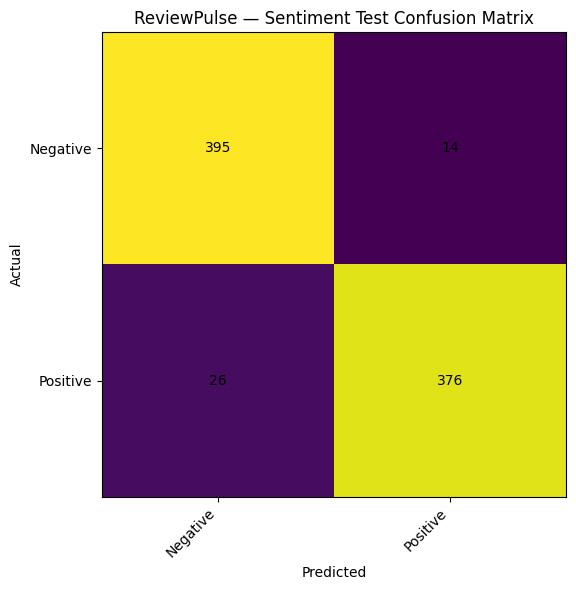

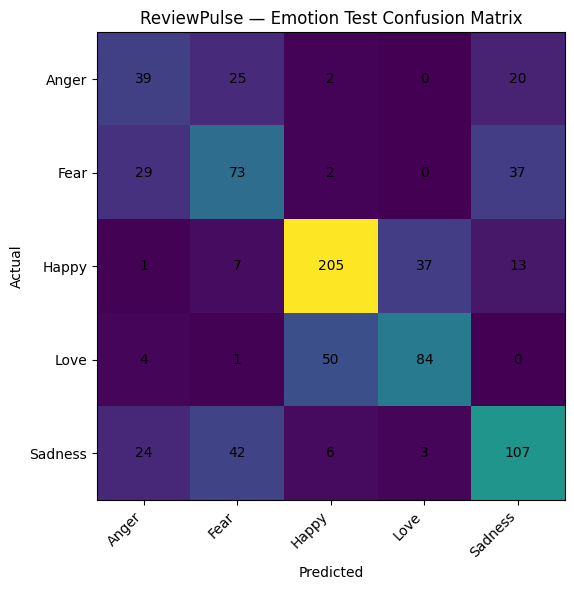

In [19]:
sentiment_labels = sorted(work["Sentiment"].unique())
emotion_labels = sorted(work["Emotion"].unique())

save_confusion(
    test["Sentiment"],
    sentiment_test_pred,
    sentiment_labels,
    "ReviewPulse — Sentiment Test Confusion Matrix",
    ASSET_EVAL / "sentiment_test_confusion_matrix.png",
)

save_confusion(
    test["Emotion"],
    emotion_test_pred,
    emotion_labels,
    "ReviewPulse — Emotion Test Confusion Matrix",
    ASSET_EVAL / "emotion_test_confusion_matrix.png",
)

## 14. Failure analysis

In [20]:
test_out = test[
    ["Category", "Product Name", "Customer Review", "Sentiment", "Emotion"]
].copy()

test_out["sentiment_pred"] = sentiment_test_pred
test_out["emotion_pred"] = emotion_test_pred
test_out["sentiment_correct"] = test_out["Sentiment"] == test_out["sentiment_pred"]
test_out["emotion_correct"] = test_out["Emotion"] == test_out["emotion_pred"]

test_out.to_csv(REPORTS / "test_predictions.csv", index=False)

sentiment_errors = test_out[~test_out["sentiment_correct"]].copy()
emotion_errors = test_out[~test_out["emotion_correct"]].copy()

sentiment_errors.to_csv(REPORTS / "sentiment_errors.csv", index=False)
emotion_errors.to_csv(REPORTS / "emotion_errors.csv", index=False)

print("Sentiment errors:", len(sentiment_errors))
display(sentiment_errors.head(20))
print("Emotion errors:", len(emotion_errors))
display(emotion_errors.head(20))

Sentiment errors: 40


,Category,Product Name,Customer Review,Sentiment,Emotion,sentiment_pred,emotion_pred,sentiment_correct,emotion_correct
112,Computers and Laptops,RB - C78 Meja Laptop Lipat Portable Meja Belaj...,BANYAKK RUSAKK DAN LECET NYAAAA !!!!,Negative,Anger,Positive,Happy,False,False
147,Computers and Laptops,Fantech OCA258 / OC-A258 Kursi Kerja Kantor Pr...,mantab minnn pengiriman jam 5 sore masih di ga...,Positive,Love,Negative,Anger,False,False
253,Toys and Hobbies,Laba Laba Mainan Dekorasi Halloween Spider Toy...,harga segini kurang worth it.bahan tidak tebal...,Negative,Sadness,Positive,Fear,False,False
467,Food and Drink,TUKU - TUKUCUR Kopi Susu Tetangga 1 Liter - No...,aku dikirimin kopi langsung masukin kulkas. be...,Negative,Sadness,Positive,Sadness,False,True
549,Food and Drink,Rendang Padang Level 3 - Daging Sapi (250gr),"rendangnya enakkk, dagingnya empukkk. Paling s...",Positive,Love,Negative,Fear,False,False
874,Automotive,Masker Sport SHERLOCK Olahraga Sepeda Dual Val...,gak nyaman dipakai.,Negative,Sadness,Positive,Happy,False,False
1478,Party Supplies and Craft,Stick Cup Standing Balon / Tatakan balon / Tia...,"NOT RECOMENDED SELLER ,gara2 Ini toko .. surpr...",Negative,Sadness,Positive,Love,False,False
1528,Party Supplies and Craft,box clover segi 4 / kotak kado hadiah gift mak...,Bagusssss bangeeettttt ????????????,Positive,Love,Negative,Anger,False,False
2010,Sport,MINISO Matras Yoga Pola Garis Tubuh 5mm Matras...,"Nyaman, ga licin, mantebbb",Positive,Happy,Negative,Happy,False,True
2090,Sport,BAM Pengeras Aroma Tawar 100Gram,KURIR JNE ******** ******,Negative,Anger,Positive,Anger,False,True


Emotion errors: 303


,Category,Product Name,Customer Review,Sentiment,Emotion,sentiment_pred,emotion_pred,sentiment_correct,emotion_correct
30,Computers and Laptops,cooling pad laptop tahan 24 jam 6.000 Rpm angi...,Penjualnya Ramah Melayani Pembeli Dengan Sabar...,Positive,Happy,Positive,Love,True,False
42,Computers and Laptops,Kabel Power Adaptor Charger Laptop 3 Lubang,gak bisa di pakai??,Negative,Sadness,Negative,Fear,True,False
60,Computers and Laptops,Mouse Wireless Komic KM-803 - 1200DPI Nano USB...,boros batre,Negative,Sadness,Negative,Anger,True,False
81,Computers and Laptops,Adaptor Charger Laptop Asus A455LA A455LD A455...,"Kualitas chargeran jelek bangettt, baru tiga H...",Negative,Anger,Negative,Sadness,True,False
84,Computers and Laptops,Logitech MK275 Wireless Keyboard Mouse Combo,"cepet rusak, kadang konek kadang engga",Negative,Anger,Negative,Fear,True,False
93,Computers and Laptops,Telkomsel Orbit Star 2,"Chat tidak di balas, Kuota yang di janjikan 50...",Negative,Anger,Negative,Fear,True,False
106,Computers and Laptops,Mouse Gaming/ Gaming Mouse Terlaris HP M160 - ...,"Belanja dari Official Store, kondisi barang di...",Negative,Anger,Negative,Happy,True,False
112,Computers and Laptops,RB - C78 Meja Laptop Lipat Portable Meja Belaj...,BANYAKK RUSAKK DAN LECET NYAAAA !!!!,Negative,Anger,Positive,Happy,False,False
147,Computers and Laptops,Fantech OCA258 / OC-A258 Kursi Kerja Kantor Pr...,mantab minnn pengiriman jam 5 sore masih di ga...,Positive,Love,Negative,Anger,False,False
151,Computers and Laptops,Fantech OCA258 / OC-A258 Kursi Kerja Kantor Pr...,"As always gapernah gagal belanja sini, thanks ggs",Positive,Love,Positive,Happy,True,False


## 15. Category-level audit

In [21]:
def category_audit(frame, true_col, pred_col):
    rows = []
    for category, g in frame.groupby("Category"):
        if len(g) < 10:
            continue
        rows.append({
            "Category": category,
            "N": len(g),
            "MacroF1": f1_score(g[true_col], g[pred_col], average="macro"),
            "Accuracy": accuracy_score(g[true_col], g[pred_col]),
        })
    return pd.DataFrame(rows).sort_values(["MacroF1", "N"], ascending=[True, False])

sentiment_category_audit = category_audit(
    test_out, "Sentiment", "sentiment_pred"
)
emotion_category_audit = category_audit(
    test_out, "Emotion", "emotion_pred"
)

display(sentiment_category_audit.head(15))
display(emotion_category_audit.head(15))

sentiment_category_audit.to_csv(REPORTS / "sentiment_category_audit.csv", index=False)
emotion_category_audit.to_csv(REPORTS / "emotion_category_audit.csv", index=False)

,Category,N,MacroF1,Accuracy
23,Precious Metal,12,0.478261,0.916667
25,Tour and Travel,19,0.486486,0.947368
5,Camera,29,0.790865,0.793103
14,Kitchen,29,0.882591,0.896552
4,Books,29,0.894545,0.896552
10,Gaming,29,0.896057,0.896552
27,Women's Fashion,34,0.911072,0.911765
15,Men's Fashion,27,0.920588,0.925926
7,Computers and Laptops,30,0.920635,0.933333
21,Party Supplies and Craft,31,0.926190,0.935484


,Category,N,MacroF1,Accuracy
14,Kitchen,29,0.267836,0.655172
27,Women's Fashion,34,0.365416,0.500000
12,Household,33,0.373367,0.515152
8,Electronics,29,0.447819,0.586207
15,Men's Fashion,27,0.456190,0.555556
21,Party Supplies and Craft,31,0.471232,0.483871
17,Movies and Music,32,0.475291,0.593750
25,Tour and Travel,19,0.482906,0.736842
4,Books,29,0.486735,0.620690
6,Carpentry,30,0.495425,0.600000


## 16. Keyword / issue summary

This is an **interpretable lexical summary**, not a causal topic model and not proof that a keyword is the root cause of a complaint.

The function ranks TF-IDF terms inside a selected subset of reviews.

In [22]:
def top_tfidf_terms(texts, top_n=20, ngram_range=(1,2)):
    texts = pd.Series(texts).dropna().astype(str)
    if len(texts) == 0:
        return pd.DataFrame(columns=["term", "score"])

    vec = TfidfVectorizer(
        lowercase=True,
        ngram_range=ngram_range,
        min_df=2 if len(texts) >= 20 else 1,
        max_features=20000,
        sublinear_tf=True,
    )
    X = vec.fit_transform(texts)
    scores = np.asarray(X.mean(axis=0)).ravel()
    terms = np.asarray(vec.get_feature_names_out())
    order = np.argsort(-scores)[:top_n]

    return pd.DataFrame({
        "term": terms[order],
        "score": scores[order],
    })

negative_keywords = top_tfidf_terms(
    trainval.loc[trainval["Sentiment"] == "Negative", "review_text"],
    top_n=30,
)
display(negative_keywords.head(20))
negative_keywords.to_csv(REPORTS / "negative_review_keywords.csv", index=False)

,term,score
0,tidak,0.030614
1,di,0.025830
2,barang,0.025481
3,yg,0.025171
4,ada,0.020097
5,nya,0.019993
6,ga,0.019477
7,sesuai,0.019191
8,dan,0.018771
9,kecewa,0.018610


In [23]:
emotion_keyword_tables = []

for emotion in sorted(trainval["Emotion"].unique()):
    table = top_tfidf_terms(
        trainval.loc[trainval["Emotion"] == emotion, "review_text"],
        top_n=15,
    )
    table.insert(0, "Emotion", emotion)
    emotion_keyword_tables.append(table)

emotion_keywords = pd.concat(emotion_keyword_tables, ignore_index=True)
display(emotion_keywords.head(30))
emotion_keywords.to_csv(REPORTS / "emotion_keywords.csv", index=False)

,Emotion,term,score
0,Anger,barang,0.033327
1,Anger,di,0.029956
2,Anger,tidak,0.029422
3,Anger,yg,0.028736
4,Anger,ga,0.027788
5,Anger,jelek,0.025381
6,Anger,nya,0.023875
7,Anger,dikirim,0.023265
8,Anger,lama,0.023236
9,Anger,ada,0.023125


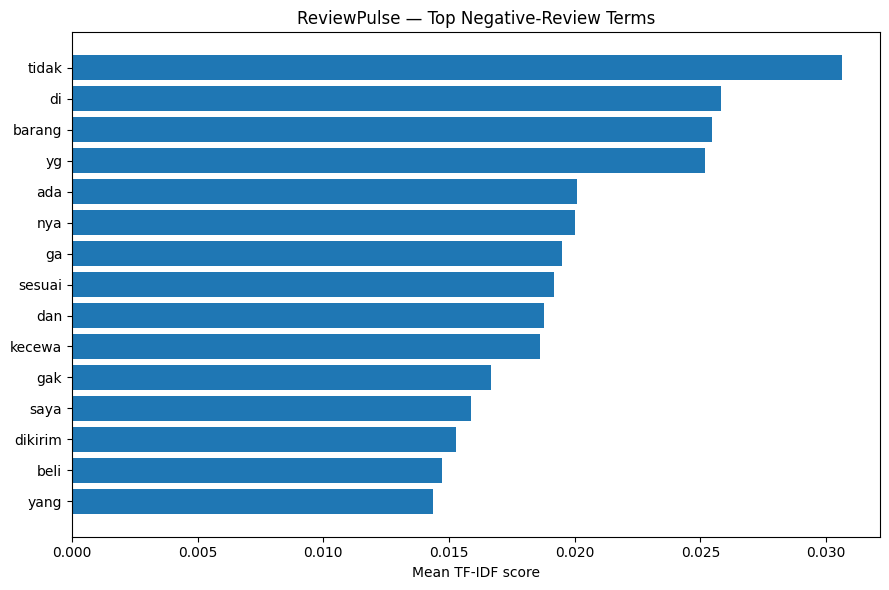

In [24]:
top_negative = negative_keywords.head(15).sort_values("score")
plt.figure(figsize=(9,6))
plt.barh(top_negative["term"], top_negative["score"])
plt.xlabel("Mean TF-IDF score")
plt.title("ReviewPulse — Top Negative-Review Terms")
plt.tight_layout()
plt.savefig(ASSET_PRED / "negative_review_top_terms.png", dpi=180, bbox_inches="tight")
plt.show()

## 17. Product-style summary function

In [25]:
def summarize_reviews(frame: pd.DataFrame, top_n_keywords: int = 10):
    required = {"Customer Review"}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    tmp = frame.copy()
    tmp["review_text"] = tmp["Customer Review"].astype(str).str.strip()

    tmp["predicted_sentiment"] = sentiment_champion.predict(tmp["review_text"])
    tmp["predicted_emotion"] = emotion_champion.predict(tmp["review_text"])

    summary = {
        "rows": int(len(tmp)),
        "sentiment_counts": tmp["predicted_sentiment"].value_counts().to_dict(),
        "emotion_counts": tmp["predicted_emotion"].value_counts().to_dict(),
    }

    negative_terms = top_tfidf_terms(
        tmp.loc[tmp["predicted_sentiment"] == "Negative", "review_text"],
        top_n=top_n_keywords,
    )

    return tmp, summary, negative_terms

demo_input = test.head(25).copy()
demo_pred, demo_summary, demo_keywords = summarize_reviews(demo_input)

print(json.dumps(demo_summary, indent=2, ensure_ascii=False))
display(demo_pred.head())
display(demo_keywords)

{
  "rows": 25,
  "sentiment_counts": {
    "Negative": 16,
    "Positive": 9
  },
  "emotion_counts": {
    "Happy": 7,
    "Sadness": 7,
    "Anger": 5,
    "Fear": 3,
    "Love": 3
  }
}


,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion,review_text,review_group,predicted_sentiment,predicted_emotion
4,Computers and Laptops,ADAPTOR CHARGER MONITOR LCD LED TV LG merek LG...,Jakarta Timur,55000,4.7,2030,672,5,"Barang Bagus, pengemasan Aman, dapat Berfungsi...",Positive,Happy,"Barang Bagus, pengemasan Aman, dapat Berfungsi...","barang bagus, pengemasan aman, dapat berfungsi...",Positive,Happy
11,Computers and Laptops,Adaptor Charger Laptop Asus A455LA A455LD A455...,Jakarta Utara,66000,4.8,2702,882,5,alhamdulillah barangnya udah nyampe... d coba ...,Positive,Happy,alhamdulillah barangnya udah nyampe... d coba ...,alhamdulillah barangnya udah nyampe... d coba ...,Positive,Happy
17,Computers and Laptops,kipas laptop cooling pad Ace cooling ergostand...,Jakarta Utara,80000,4.8,3982,1890,5,barang udah sampai ya gan dan berfungsi. terim...,Positive,Happy,barang udah sampai ya gan dan berfungsi. terim...,barang udah sampai ya gan dan berfungsi. terim...,Positive,Happy
24,Computers and Laptops,Cooler Master Notepal CMC3 Silent Fan Laptop C...,Jakarta Barat,112000,4.9,5988,2969,5,silent dan bagus untuk pekerjaan ringan,Positive,Happy,silent dan bagus untuk pekerjaan ringan,silent dan bagus untuk pekerjaan ringan,Positive,Happy
30,Computers and Laptops,cooling pad laptop tahan 24 jam 6.000 Rpm angi...,Kota Surabaya,385000,5.0,2716,1843,5,Penjualnya Ramah Melayani Pembeli Dengan Sabar...,Positive,Happy,Penjualnya Ramah Melayani Pembeli Dengan Sabar...,penjualnya ramah melayani pembeli dengan sabar...,Positive,Love


,term,score
0,di,0.066136
1,barang,0.047100
2,gak,0.047037
3,rusak,0.045868
4,kurang,0.042636
5,batre,0.036084
6,boros,0.036084
7,boros batre,0.036084
8,pakai,0.035530
9,dan,0.034555


## 18. Example inference artifact

In [26]:
sample_columns = [
    "Category", "Product Name", "Customer Review",
    "Sentiment", "Emotion", "sentiment_pred", "emotion_pred"
]
test_out[sample_columns].head(100).to_csv(
    ASSET_PRED / "sample_predictions.csv", index=False
)

sample_upload = test[["Category", "Product Name", "Customer Review"]].head(100).copy()
sample_upload.to_csv(WORK / "reviewpulse_sample_input.csv", index=False)

print("Saved:", WORK / "reviewpulse_sample_input.csv")

Saved: /kaggle/working/reviewpulse_15pct/reviewpulse_sample_input.csv


## 19. Optional transformer experiment

The source text is Indonesian, so a future transformer experiment should use an Indonesian-capable model rather than assuming an English encoder.

This baseline notebook intentionally makes TF-IDF the reproducible default.  
A transformer should only replace it if it wins under the same group-aware validation protocol.

Suggested future candidates:
- IndoBERT-family sequence classifier;
- multilingual transformer with Indonesian coverage.

Do **not** report transformer metrics until the experiment has actually been run.

## 20. Final summary and claim boundaries

In [27]:
final_summary = {
    "project": "ReviewPulse",
    "portfolio_progress": "15%",
    "task": {
        "sentiment": "Indonesian product-review sentiment classification",
        "emotion": "Indonesian product-review emotion classification",
        "summary": "TF-IDF keyword summary for negative reviews",
    },
    "source_audit": audit,
    "split_policy": "group-aware split by normalized review text",
    "model_selection": selection,
    "official_test": official,
    "claim_boundaries": {
        "supported": [
            "sentiment classification on the audited PRDECT-ID split",
            "emotion classification on the audited PRDECT-ID split",
            "TF-IDF lexical keyword summary",
            "group-aware held-out evaluation",
        ],
        "unsupported": [
            "causal root-cause analysis",
            "universal marketplace performance",
            "customer intent certainty",
            "business KPI impact without external validation",
        ],
    },
}

print(json.dumps(final_summary, indent=2, ensure_ascii=False))
(REPORTS / "final_summary.json").write_text(
    json.dumps(final_summary, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

{
  "project": "ReviewPulse",
  "portfolio_progress": "15%",
  "task": {
    "sentiment": "Indonesian product-review sentiment classification",
    "emotion": "Indonesian product-review emotion classification",
    "summary": "TF-IDF keyword summary for negative reviews"
  },
  "source_audit": {
    "rows": 5400,
    "columns": 11,
    "missing_cells": 0,
    "full_row_duplicates": 7,
    "duplicate_review_text_rows": 95,
    "unique_review_texts": 5305,
    "sentiment_counts": {
      "Negative": 2821,
      "Positive": 2579
    },
    "emotion_counts": {
      "Happy": 1770,
      "Sadness": 1202,
      "Fear": 920,
      "Love": 809,
      "Anger": 699
    },
    "category_counts": {
      "Computers and Laptops": 200,
      "Toys and Hobbies": 200,
      "Food and Drink": 200,
      "Office & Stationery": 200,
      "Automotive": 200,
      "Animal Care": 200,
      "Body Care": 200,
      "Party Supplies and Craft": 200,
      "Carpentry": 200,
      "Other Products": 200,
      "

2749

## 21. Package outputs

In [28]:
package_root = Path("/kaggle/working/reviewpulse_15pct_FINAL")
if package_root.exists():
    shutil.rmtree(package_root)

shutil.copytree(WORK, package_root)

zip_path = shutil.make_archive(
    "/kaggle/working/reviewpulse_15pct_FINAL",
    "zip",
    root_dir=str(package_root),
)

print("=== FINAL PACKAGE ===")
print("Folder:", package_root)
print("ZIP:", zip_path)
print("Sentiment model:", MODELS / "reviewpulse_sentiment_tfidf.joblib")
print("Emotion model:", MODELS / "reviewpulse_emotion_tfidf.joblib")
print("Reports:", REPORTS)
print("Assets:", WORK / "assets")

=== FINAL PACKAGE ===
Folder: /kaggle/working/reviewpulse_15pct_FINAL
ZIP: /kaggle/working/reviewpulse_15pct_FINAL.zip
Sentiment model: /kaggle/working/reviewpulse_15pct/models/reviewpulse_sentiment_tfidf.joblib
Emotion model: /kaggle/working/reviewpulse_15pct/models/reviewpulse_emotion_tfidf.joblib
Reports: /kaggle/working/reviewpulse_15pct/reports
Assets: /kaggle/working/reviewpulse_15pct/assets


## Before → Now → Next

### Before
A generic “sentiment analysis” idea.

### Now
A reproducible Indonesian review-analysis MVP with:
- dataset audit;
- duplicate / conflict checks;
- group-aware splitting;
- separate sentiment and emotion tasks;
- TF-IDF baselines;
- held-out evaluation;
- lexical complaint summary;
- exportable artifacts.

### Next
1. Build the Streamlit dashboard.
2. Add an Indonesian transformer candidate under the same split.
3. Compare inference latency and validation Macro-F1.
4. Add seller-facing summary cards and CSV export.
5. Document dataset provenance/license before redistributing any raw data.